In [23]:
!pip -q install prody biopython scipy numpy pandas matplotlib rdkit pdbfixer openmm

# Install system dependencies
!apt-get update -qq
!apt-get install -y -qq git build-essential

# Clone official fpocket repository
!git clone https://github.com/Discngine/fpocket.git /content/fpocket

# Compile fpocket
%cd /content/fpocket
!make

# Verify installation
!./bin/fpocket -h

import os, re, json, time, shutil, subprocess, copy, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree, distance
from Bio.PDB import PDBParser, PDBIO, Select, is_aa
from prody import ANM, parsePDB

from rdkit import Chem, RDConfig
from rdkit.Chem import ChemicalFeatures

from pdbfixer import PDBFixer
from openmm.app import PDBFile

from collections import Counter

SEED = 42
rng = np.random.default_rng(SEED)
print("fpocket:", shutil.which("fpocket"))


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
fatal: destination path '/content/fpocket' already exists and is not an empty directory.
/content/fpocket
cd src/qhull/ && make
make[1]: Entering directory '/content/fpocket/src/qhull'
mkdir -p bin lib
make[1]: Leaving directory '/content/fpocket/src/qhull'
***** POCKET HUNTING BEGINS ***** 
! Invalid pdb name given.

:||: fpocket 4.0 :||:
        
Mandatory parameters : 
	fpocket -f --file pdb or cif file                                      
	[ fpocket -F --fileList fileList ]                                  


Optional output parameters
	-x --calculate_interaction_grids	: Specify this flag if you want fpocket to     
						  calculate VdW and Coulomb grids for each pocket
	-d --pocket_descr_stdout		: Put this flag if you want to write fpocket
						  descriptors to the standard output


Optional 

In [24]:
import os

FPOCKET_BIN = "/content/fpocket/bin/fpocket"

assert os.path.exists(FPOCKET_BIN), "fpocket compilation failed!"

os.environ["PATH"] += os.pathsep + "/content/fpocket/bin"

!which fpocket
!fpocket -h

/content/fpocket/bin/fpocket
***** POCKET HUNTING BEGINS ***** 
! Invalid pdb name given.

:||: fpocket 4.0 :||:
        
Mandatory parameters : 
	fpocket -f --file pdb or cif file                                      
	[ fpocket -F --fileList fileList ]                                  


Optional output parameters
	-x --calculate_interaction_grids	: Specify this flag if you want fpocket to     
						  calculate VdW and Coulomb grids for each pocket
	-d --pocket_descr_stdout		: Put this flag if you want to write fpocket
						  descriptors to the standard output


Optional input parameters
	-l --model_number (int)			: Number of Model to analyze.	
	-y --topology_file (string)		: File name of a topology file (Amber prmtop).	
	-r --custom_ligand (string)		: String specifying a ligand like: 
						  residuenumber:residuename:chain_code (ie. 1224:PU8:A).	
	-P --custom_pocket (string)		: String specifying a pocket like: 
						  residuenumber1:insertion_code1('-' if empty):chain_code1.resi

In [25]:
from google.colab import files

INPUT_DIR = Path("/content/pharmacophore_project/input")
OUTPUT_DIR = Path("/content/data/stage1")

CONF_DIR = OUTPUT_DIR / "pocket_conformers"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
INPUT_DIR.mkdir(parents=True, exist_ok=True)
CONF_DIR.mkdir(parents=True, exist_ok=True)
for d in (INPUT_DIR, OUTPUT_DIR, CONF_DIR):
    d.mkdir(parents=True, exist_ok=True)

PDB_ID = None  # e.g. "1AKE"; leave None to upload
if PDB_ID:
    from Bio.PDB import PDBList
    downloaded = PDBList().retrieve_pdb_file(PDB_ID, pdir=str(INPUT_DIR),
                                              file_format="pdb", overwrite=True)
    PDB_FILE = Path(downloaded)
else:
    uploaded = files.upload()
    candidates = [n for n in uploaded if n.lower().endswith((".pdb", ".ent"))]
    if not candidates:
        raise ValueError("Upload a .pdb or .ent file.")
    PDB_FILE = INPUT_DIR / candidates[0]
    PDB_FILE.write_bytes(uploaded[candidates[0]])

# Ensemble parameters
K = 5                    # use >=10 for a first sensitivity analysis; test 20-50 later
N_MODES = 10               # low-frequency non-trivial modes
# ANM_CUTOFF = 15.0          # Angstrom
BASE_ANM_CUTOFF = 15.0      # Default for standard/large proteins (>150 residues)
SMALL_PROTEIN_CUTOFF = 11.0 # Adjusted cutoff for small/compact proteins (<=150 residues)
TARGET_CA_RMSD = 0.5
INTERPOLATION_K = 4
RANDOM_SEED = 42

print("Input:", PDB_FILE)


Saving 7ONS.pdb to 7ONS.pdb
Input: /content/pharmacophore_project/input/7ONS.pdb


In [26]:
parser = PDBParser(QUIET=True)
structure = parser.get_structure("input", str(PDB_FILE))

class ProteinHeavyAtoms(Select):
    def accept_atom(self, atom):
        residue = atom.get_parent()
        return (is_aa(residue, standard=True)
                and atom.element.upper() not in {"H", "D"}
                and (not atom.is_disordered() or atom.get_altloc() in {"A", " "}))

CLEAN_PDB = INPUT_DIR / "protein_clean.pdb"
writer = PDBIO()
writer.set_structure(structure)
writer.save(str(CLEAN_PDB), ProteinHeavyAtoms())

if shutil.which("fpocket") is None:
    raise RuntimeError("fpocket installation failed.")
t0 = time.perf_counter()
run = subprocess.run(["fpocket", "-f", str(CLEAN_PDB)], capture_output=True, text=True)
if run.returncode != 0:
    raise RuntimeError(run.stderr[-3000:])
POCKET_DIR = CLEAN_PDB.with_name(CLEAN_PDB.stem + "_out")
INFO_FILE = POCKET_DIR / f"{CLEAN_PDB.stem}_info.txt"
POCKETS_DIR = POCKET_DIR / "pockets"
if not INFO_FILE.exists():
    raise FileNotFoundError(INFO_FILE)
print("fpocket seconds:", round(time.perf_counter()-t0, 2))
print("Pocket output:", POCKET_DIR)


fpocket seconds: 8.91
Pocket output: /content/pharmacophore_project/input/protein_clean_out


In [27]:
# ==========================================
# CELL 3A: CHEMICAL PROTEIN PREPARATION
# ==========================================

CHEMISTRY_PDB = INPUT_DIR / "protein_chemistry.pdb"

# Load cleaned protein
fixer = PDBFixer(filename=str(CLEAN_PDB))

# Identify missing residues
fixer.findMissingResidues()

# Do not automatically reconstruct missing loops.
fixer.missingResidues = {}

# Identify non-standard residues
fixer.findNonstandardResidues()

print("Non-standard residues:",
      fixer.nonstandardResidues)

# Identify missing atoms
fixer.findMissingAtoms()

print("Missing heavy atoms:",
      fixer.missingAtoms)

print("Missing terminal atoms:",
      fixer.missingTerminals)

# Add missing heavy atoms where possible
fixer.addMissingAtoms()

# Add hydrogens using the selected pH assumption
fixer.addMissingHydrogens(pH=7.4)

# Save chemically prepared structure
with open(CHEMISTRY_PDB, "w") as output:
    PDBFile.writeFile(
        fixer.topology,
        fixer.positions,
        output,
        keepIds=True
    )

print("Chemical protein preparation completed.")
print("Saved:", CHEMISTRY_PDB)

Non-standard residues: []
Missing heavy atoms: {<Residue 0 (LYS) of chain 0>: [<Atom 3 (CG) of chain 0 residue 0 (LYS)>, <Atom 4 (CD) of chain 0 residue 0 (LYS)>, <Atom 5 (CE) of chain 0 residue 0 (LYS)>, <Atom 6 (NZ) of chain 0 residue 0 (LYS)>], <Residue 2 (LYS) of chain 0>: [<Atom 3 (CG) of chain 0 residue 0 (LYS)>, <Atom 4 (CD) of chain 0 residue 0 (LYS)>, <Atom 5 (CE) of chain 0 residue 0 (LYS)>, <Atom 6 (NZ) of chain 0 residue 0 (LYS)>], <Residue 66 (GLN) of chain 0>: [<Atom 3 (CG) of chain 0 residue 0 (GLN)>, <Atom 4 (CD) of chain 0 residue 0 (GLN)>, <Atom 5 (OE1) of chain 0 residue 0 (GLN)>, <Atom 6 (NE2) of chain 0 residue 0 (GLN)>], <Residue 147 (GLU) of chain 0>: [<Atom 3 (CG) of chain 0 residue 0 (GLU)>, <Atom 4 (CD) of chain 0 residue 0 (GLU)>, <Atom 5 (OE1) of chain 0 residue 0 (GLU)>, <Atom 6 (OE2) of chain 0 residue 0 (GLU)>], <Residue 372 (LYS) of chain 1>: [<Atom 4 (CD) of chain 0 residue 0 (LYS)>, <Atom 5 (CE) of chain 0 residue 0 (LYS)>, <Atom 6 (NZ) of chain 0 resi

In [28]:
# ============================================================
# ATOM IDENTITY VALIDATION - HELPER FUNCTIONS
# ============================================================

from Bio.PDB import PDBParser, is_aa
from pathlib import Path
import pandas as pd


validation_parser = PDBParser(QUIET=True)


def get_atom_inventory(pdb_path):

    """
    Extract unique heavy-atom identities from a protein PDB.

    Identity:
    (chain, residue_number, insertion_code,
     residue_name, atom_name)

    Element is stored separately for validation.
    """

    structure = validation_parser.get_structure(
        "validation",
        str(pdb_path)
    )

    inventory = {}

    for model in structure:

        for chain in model:

            for residue in chain:

                if not is_aa(residue, standard=True):
                    continue

                for atom in residue:

                    element = atom.element.strip().upper()

                    if element in {"H", "D"}:
                        continue

                    atom_key = (
                        chain.id.strip(),
                        residue.id[1],
                        residue.id[2].strip(),
                        residue.resname.strip(),
                        atom.name.strip()
                    )

                    if atom_key in inventory:

                        raise ValueError(
                            f"Duplicate atom identity: {atom_key}"
                        )

                    inventory[atom_key] = element

        # Use the first model only.
        break

    return inventory


print("Atom identity validation functions initialized.")

Atom identity validation functions initialized.


In [29]:
# ============================================================
# COMPARE CLEAN AND CHEMISTRY PROTEIN ATOMS
# ============================================================

clean_inventory = get_atom_inventory(CLEAN_PDB)

chemistry_inventory = get_atom_inventory(CHEMISTRY_PDB)


clean_atoms = set(clean_inventory.keys())

chemistry_atoms = set(chemistry_inventory.keys())


# ------------------------------------------------------------
# IDENTIFY MISSING AND ADDITIONAL ATOMS
# ------------------------------------------------------------

missing_in_chemistry = clean_atoms - chemistry_atoms

additional_in_chemistry = chemistry_atoms - clean_atoms

common_atoms = clean_atoms.intersection(chemistry_atoms)


# ------------------------------------------------------------
# CHECK ELEMENT CONSISTENCY
# ------------------------------------------------------------

element_mismatches = []

for atom_id in common_atoms:

    clean_element = clean_inventory[atom_id]

    chemistry_element = chemistry_inventory[atom_id]

    if clean_element != chemistry_element:

        element_mismatches.append({

            "atom_identity": atom_id,

            "clean_element": clean_element,

            "chemistry_element": chemistry_element

        })


# ------------------------------------------------------------
# GENERATE REPORT
# ------------------------------------------------------------

print("\n========== PROTEIN ATOM MAPPING REPORT ==========")

print("Clean protein atoms:", len(clean_atoms))

print("Chemistry protein atoms:", len(chemistry_atoms))

print("Common atoms:", len(common_atoms))

print("Missing in chemistry structure:",
      len(missing_in_chemistry))

print("Additional chemistry atoms:",
      len(additional_in_chemistry))

print("Element mismatches:",
      len(element_mismatches))


# ------------------------------------------------------------
# COVERAGE
# ------------------------------------------------------------

coverage = (
    len(common_atoms) / max(len(clean_atoms), 1)
)

print("\nClean protein atom coverage:",
      round(coverage * 100, 2), "%")


# ------------------------------------------------------------
# SAVE VALIDATION REPORT
# ------------------------------------------------------------

mapping_report = []

for atom_id in sorted(clean_atoms | chemistry_atoms):

    mapping_report.append({

        "chain": atom_id[0],

        "residue_number": atom_id[1],

        "insertion_code": atom_id[2],

        "residue_name": atom_id[3],

        "atom_name": atom_id[4],

        "clean_element": clean_inventory.get(atom_id),

        "chemistry_element": chemistry_inventory.get(atom_id),

        "present_in_clean": atom_id in clean_atoms,

        "present_in_chemistry": atom_id in chemistry_atoms,

        "matched": atom_id in common_atoms

    })


mapping_df = pd.DataFrame(mapping_report)

mapping_df.to_csv(
    OUTPUT_DIR / "protein_atom_mapping_report.csv",
    index=False
)

print("\nAtom mapping report saved.")


========== PROTEIN ATOM MAPPING REPORT ==========
Clean protein atoms: 5445
Chemistry protein atoms: 5494
Common atoms: 5445
Missing in chemistry structure: 0
Additional chemistry atoms: 49
Element mismatches: 0

Clean protein atom coverage: 100.0 %

Atom mapping report saved.


In [30]:
# ============================================================
# CREATE VALIDATED ATOM IDENTITY SET
# ============================================================

# Only atoms present in both structures
# with matching element identities are accepted.

validated_atom_ids = {

    atom_id

    for atom_id in common_atoms

    if clean_inventory[atom_id] == chemistry_inventory[atom_id]

}


print("========== VALIDATED ATOM IDENTITIES ==========")

print("Validated heavy atoms:", len(validated_atom_ids))

print("Excluded atoms:",
      len(chemistry_atoms - validated_atom_ids))


if len(validated_atom_ids) == 0:

    raise RuntimeError(
        "No common validated atoms found. "
        "Check protein preparation and PDB atom identities."
    )

========== VALIDATED ATOM IDENTITIES ==========
Validated heavy atoms: 5445
Excluded atoms: 49


In [31]:
from rdkit import Chem

# ============================================================
# 1. LOAD PREPARED PROTEIN
# ============================================================

rdkit_mol = Chem.MolFromPDBFile(
    str(CHEMISTRY_PDB),
    sanitize=False,
    removeHs=False,
    proximityBonding=True
)

if rdkit_mol is None:
    raise RuntimeError(
        "RDKit could not read the prepared protein PDB."
    )

print("Protein structure loaded into RDKit.")
print("Initial atoms:", rdkit_mol.GetNumAtoms())
print("Initial bonds:", rdkit_mol.GetNumBonds())


# ============================================================
# 2. CORRECT INCORRECT TERMINAL O-OXT CONNECTIVITY
# ============================================================

rw_mol = Chem.RWMol(rdkit_mol)

removed_bonds = []

for bond in list(rdkit_mol.GetBonds()):

    atom1 = bond.GetBeginAtom()
    atom2 = bond.GetEndAtom()

    info1 = atom1.GetPDBResidueInfo()
    info2 = atom2.GetPDBResidueInfo()

    if info1 is None or info2 is None:
        continue

    # Check whether both atoms belong to the same residue
    same_residue = (
        info1.GetChainId() == info2.GetChainId()
        and info1.GetResidueNumber() == info2.GetResidueNumber()
        and info1.GetInsertionCode() == info2.GetInsertionCode()
        and info1.GetResidueName() == info2.GetResidueName()
    )

    atom_names = {
        info1.GetName().strip(),
        info2.GetName().strip()
    }

    # Identify an incorrectly inferred O-OXT bond
    is_terminal_oxygen_bond = (
        same_residue
        and atom1.GetSymbol() == "O"
        and atom2.GetSymbol() == "O"
        and atom_names == {"O", "OXT"}
    )

    if is_terminal_oxygen_bond:

        rw_mol.RemoveBond(
            atom1.GetIdx(),
            atom2.GetIdx()
        )

        removed_bonds.append({
            "chain": info1.GetChainId(),
            "residue": info1.GetResidueName(),
            "residue_number": info1.GetResidueNumber()
        })


# ============================================================
# 3. RECONSTRUCT MOLECULAR GRAPH
# ============================================================

rdkit_mol = rw_mol.GetMol()

print("\nIncorrect O-OXT bonds removed:", len(removed_bonds))

if removed_bonds:
    print("Affected residues:")

    for residue in removed_bonds:
        print(residue)


# ============================================================
# 4. MOLECULAR GRAPH SANITIZATION
# ============================================================

try:

    Chem.SanitizeMol(rdkit_mol)

    print("\nRDKit molecular graph successfully sanitized.")

except Exception as e:

    raise RuntimeError(
        "Molecular graph sanitization failed. "
        "Additional connectivity errors may exist.\n"
        f"RDKit error: {e}"
    )


# ============================================================
# 5. FINAL MOLECULAR GRAPH SUMMARY
# ============================================================

print("\n========== MOLECULAR GRAPH SUMMARY ==========")

print("Total atoms:", rdkit_mol.GetNumAtoms())
print("Total bonds:", rdkit_mol.GetNumBonds())

print(
    "Molecular graph validity:",
    "PASS" if rdkit_mol.GetNumAtoms() > 0 else "FAIL"
)

print("Protein chemistry preparation validated.")

Protein structure loaded into RDKit.
Initial atoms: 11074
Initial bonds: 11179

Incorrect O-OXT bonds removed: 2
Affected residues:
{'chain': 'A', 'residue': 'THR', 'residue_number': 1011}
{'chain': 'B', 'residue': 'THR', 'residue_number': 1011}

RDKit molecular graph successfully sanitized.

========== MOLECULAR GRAPH SUMMARY ==========
Total atoms: 11074
Total bonds: 11177
Molecular graph validity: PASS
Protein chemistry preparation validated.


In [32]:
# ============================================================
# CELL 3C: RDKit CHEMICAL FEATURE PERCEPTION
# ============================================================

from rdkit import RDConfig
from rdkit.Chem import ChemicalFeatures
from collections import Counter
import os
import pandas as pd

# ------------------------------------------------------------
# 1. INITIALIZE RDKit FEATURE FACTORY
# ------------------------------------------------------------

fdef_path = os.path.join(
    RDConfig.RDDataDir,
    "BaseFeatures.fdef"
)

if not os.path.exists(fdef_path):
    raise FileNotFoundError(
        "RDKit BaseFeatures.fdef file not found."
    )

feature_factory = ChemicalFeatures.BuildFeatureFactory(
    fdef_path
)

print("RDKit chemical feature factory initialized.")


# ------------------------------------------------------------
# 2. EXTRACT CHEMICAL FEATURES
# ------------------------------------------------------------

if rdkit_mol is None:
    raise ValueError("Molecular graph is not available.")

protein_features = feature_factory.GetFeaturesForMol(
    rdkit_mol
)

print("\nChemical feature perception completed.")
print("Total chemical features:", len(protein_features))


# ------------------------------------------------------------
# 3. COUNT FEATURES BY FAMILY
# ------------------------------------------------------------

feature_counts = Counter(
    feature.GetFamily()
    for feature in protein_features
)

print("\n========== FEATURE DISTRIBUTION ==========")

for family, count in sorted(feature_counts.items()):
    print(f"{family}: {count}")


# ------------------------------------------------------------
# 4. MAP FEATURES TO PROTEIN ATOMS AND RESIDUES
# ------------------------------------------------------------

feature_records = []

for feature_id, feature in enumerate(protein_features):

    atom_ids = feature.GetAtomIds()

    atom_metadata = []

    for atom_id in atom_ids:

        atom = rdkit_mol.GetAtomWithIdx(atom_id)
        info = atom.GetPDBResidueInfo()

        if info is None:
            continue

        atom_metadata.append({
            "atom_index": atom_id,
            "atom_name": info.GetName().strip(),
            "element": atom.GetSymbol(),
            "residue_name": info.GetResidueName(),
            "residue_number": info.GetResidueNumber(),
            "chain": info.GetChainId(),
            "insertion_code": info.GetInsertionCode().strip()
        })

    feature_records.append({

        "feature_id": feature_id,

        "family": feature.GetFamily(),

        "type": feature.GetType(),

        "atom_ids": list(atom_ids),

        "atoms": atom_metadata,

        "num_atoms": len(atom_ids)

    })


# ------------------------------------------------------------
# 5. CREATE FEATURE DATAFRAME
# ------------------------------------------------------------

feature_df = pd.DataFrame(feature_records)

print("\n========== FEATURE MAPPING ==========")

print("Mapped features:", len(feature_df))

if not feature_df.empty:

    display(
        feature_df[
            ["feature_id", "family", "type", "num_atoms"]
        ].head(10)
    )


# ------------------------------------------------------------
# 6. VALIDATE FEATURE MAPPING
# ------------------------------------------------------------

unmapped_features = sum(
    1 for record in feature_records
    if len(record["atoms"]) == 0
)

print("\n========== VALIDATION ==========")

print("Total features:", len(feature_records))
print("Features without atom metadata:", unmapped_features)

if unmapped_features == 0:
    print("Feature-to-atom mapping: PASS")
else:
    print("Feature-to-atom mapping: CHECK REQUIRED")


# ------------------------------------------------------------
# 7. SAVE FEATURE MAPPING
# ------------------------------------------------------------

feature_output = OUTPUT_DIR / "rdkit_chemical_features.csv"

feature_df.to_csv(
    feature_output,
    index=False
)

print("\nFeature mapping saved to:", feature_output)

RDKit chemical feature factory initialized.

Chemical feature perception completed.
Total chemical features: 3538

========== FEATURE DISTRIBUTION ==========
Acceptor: 1000
Aromatic: 74
Donor: 1000
Hydrophobe: 1000
LumpedHydrophobe: 141
NegIonizable: 88
PosIonizable: 147
ZnBinder: 88

========== FEATURE MAPPING ==========
Mapped features: 3538


,feature_id,family,type,num_atoms
0,0,Donor,SingleAtomDonor,1
1,1,Donor,SingleAtomDonor,1
2,2,Donor,SingleAtomDonor,1
3,3,Donor,SingleAtomDonor,1
4,4,Donor,SingleAtomDonor,1
5,5,Donor,SingleAtomDonor,1
6,6,Donor,SingleAtomDonor,1
7,7,Donor,SingleAtomDonor,1
8,8,Donor,SingleAtomDonor,1
9,9,Donor,SingleAtomDonor,1



========== VALIDATION ==========
Total features: 3538
Features without atom metadata: 0
Feature-to-atom mapping: PASS

Feature mapping saved to: /content/data/stage1/rdkit_chemical_features.csv


In [33]:
# Select exactly ONE pocket based on the highest fpocket score.

def select_best_fpocket(info_file):

    text = Path(info_file).read_text(errors="replace")

    scores = {}

    chunks = re.split(r"(?=Pocket\s+\d+\s*:)", text)

    for chunk in chunks:

        m_id = re.search(r"Pocket\s+(\d+)\s*:", chunk)
        m_score = re.search(r"Score\s*:\s*([0-9.eE+-]+)", chunk)

        if m_id and m_score:
            pocket_id = int(m_id.group(1))
            score = float(m_score.group(1))

            pocket_file = POCKETS_DIR / f"pocket{pocket_id}_atm.pdb"

            if pocket_file.exists():
                scores[pocket_id] = {
                    "pocket_id": pocket_id,
                    "score": score,
                    "file": str(pocket_file)
                }

    if not scores:
        raise RuntimeError(
            "No valid fpocket pockets with scores and PDB files found."
        )

    # Select the highest-scoring pocket
    selected = max(
        scores.values(),
        key=lambda x: x["score"]
    )

    # Keep a list containing exactly one pocket.
    pockets = [selected]

    print("========== SELECTED BINDING POCKET ==========")
    print("Pocket ID:", selected["pocket_id"])
    print("fpocket Score:", selected["score"])
    print("Pocket file:", selected["file"])
    print("Total pockets detected:", len(scores))
    print("Pockets selected:", len(pockets))

    return pockets


pockets = select_best_fpocket(INFO_FILE)

display(pd.DataFrame([
    {
        "Pocket ID": p["pocket_id"],
        "fpocket Score": p["score"],
        "PDB File": p["file"]
    }
    for p in pockets
]))

========== SELECTED BINDING POCKET ==========
Pocket ID: 1
fpocket Score: 0.064
Pocket file: /content/pharmacophore_project/input/protein_clean_out/pockets/pocket1_atm.pdb
Total pockets detected: 51
Pockets selected: 1


,Pocket ID,fpocket Score,PDB File
0,1,0.064,/content/pharmacophore_project/input/protein_c...


In [34]:
# t_anm = time.perf_counter()
# prody_atoms = parsePDB(str(CLEAN_PDB))
# ca = prody_atoms.select("protein and name CA")
# if ca is None or ca.numAtoms() < 10:
#     raise ValueError("Not enough C-alpha atoms for ANM.")

# anm = ANM("target_ANM")
# anm.buildHessian(ca, cutoff=ANM_CUTOFF, gamma=1.0)
# anm.calcModes(n_modes=min(N_MODES, max(1, 3*ca.numAtoms()-6)))
# n_modes = min(N_MODES, anm.numModes())
# if n_modes < 1:
#     raise RuntimeError("ANM did not produce non-trivial modes.")

# ca_xyz = ca.getCoords().astype(float)
# eigvecs = anm.getEigvecs()[:, :n_modes].reshape(len(ca_xyz), 3, n_modes)
# eigvals = np.asarray(anm.getEigvals()[:n_modes], dtype=float)
# print("C-alpha atoms:", len(ca_xyz), "| modes:", n_modes)
# print("Lowest non-trivial eigenvalues:", eigvals[:min(5, len(eigvals))])
# print("ANM build seconds:", round(time.perf_counter()-t_anm, 2))

# # Read the cleaned structure once; keep an identical atom ordering for coordinate updates.
# base_structure = parser.get_structure("base", str(CLEAN_PDB))
# base_atoms = [a for a in base_structure.get_atoms()
#               if is_aa(a.get_parent(), standard=True)
#               and a.element.upper() not in {"H", "D"}]
# atom_xyz = np.asarray([a.coord for a in base_atoms], dtype=float)

# tree = cKDTree(ca_xyz)
# dist, idx = tree.query(atom_xyz, k=min(INTERPOLATION_K, len(ca_xyz)))
# if idx.ndim == 1:
#     idx, dist = idx[:, None], dist[:, None]
# w = 1.0 / np.maximum(dist, 1e-3)**2
# w /= w.sum(axis=1, keepdims=True)

# def scale_to_rmsd(disp, target):
#     rmsd = np.sqrt(np.mean(np.sum(disp**2, axis=1)))
#     return disp * (target / rmsd) if rmsd > 1e-12 else disp

# rng = np.random.default_rng(RANDOM_SEED)
# # Antithetic coefficients: each random direction is paired with its negative.
# n_pairs = K // 2
# coeffs = rng.normal(size=(n_pairs, n_modes))
# coeffs = np.vstack([coeffs, -coeffs])
# if K % 2:
#     coeffs = np.vstack([coeffs, np.zeros((1, n_modes))])
# # Normalize each mode coefficient vector; avoid one mode dominating by scale.
# coeffs /= np.maximum(np.linalg.norm(coeffs, axis=1, keepdims=True), 1e-12)

# conformer_records = []
# for ci, c in enumerate(coeffs[:K]):
#     ca_disp = np.einsum("im,m->i", np.zeros((len(ca_xyz), n_modes)), c) if False else np.einsum("ijm,m->ij", eigvecs, c)
#     ca_disp = scale_to_rmsd(ca_disp, TARGET_CA_RMSD)
#     atom_disp = np.sum(ca_disp[idx] * w[:, :, None], axis=1)
#     new_structure = copy.deepcopy(base_structure)
#     new_atoms = [a for a in new_structure.get_atoms()
#                  if is_aa(a.get_parent(), standard=True)
#                  and a.element.upper() not in {"H", "D"}]
#     for atom, xyz in zip(new_atoms, atom_xyz + atom_disp):
#         atom.set_coord(xyz.astype(np.float32))
#     out = CONF_DIR / f"conformer_{ci+1:03d}.pdb"
#     io = PDBIO(); io.set_structure(new_structure); io.save(str(out))
#     conformer_records.append({"id": ci, "path": str(out), "ca_rmsd": float(np.sqrt(np.mean(np.sum(ca_disp**2,axis=1))))})

# pd.DataFrame(conformer_records)

t_anm = time.perf_counter()
prody_atoms = parsePDB(str(CLEAN_PDB))
ca = prody_atoms.select("protein and name CA")
if ca is None or ca.numAtoms() < 10:
    raise ValueError("Not enough C-alpha atoms for ANM.")

# ============================================================
# ADAPTIVE ANM CUTOFF SELECTION
# ============================================================
n_ca = ca.numAtoms()
if n_ca <= 150:
    ANM_CUTOFF = 11.0
    print(f"Compact/small protein detected ({n_ca} C-alpha atoms). Adaptive ANM_CUTOFF: {ANM_CUTOFF} Å")
else:
    ANM_CUTOFF = 15.0
    print(f"Standard/large protein detected ({n_ca} C-alpha atoms). Standard ANM_CUTOFF: {ANM_CUTOFF} Å")

anm = ANM("target_ANM")
anm.buildHessian(ca, cutoff=ANM_CUTOFF, gamma=1.0)
anm.calcModes(n_modes=min(N_MODES, max(1, 3 * n_ca - 6)))
n_modes = min(N_MODES, anm.numModes())
if n_modes < 1:
    raise RuntimeError("ANM did not produce non-trivial modes.")

ca_xyz = ca.getCoords().astype(float)
eigvecs = anm.getEigvecs()[:, :n_modes].reshape(len(ca_xyz), 3, n_modes)
eigvals = np.asarray(anm.getEigvals()[:n_modes], dtype=float)
print("C-alpha atoms:", len(ca_xyz), "| modes:", n_modes)
print("Lowest non-trivial eigenvalues:", eigvals[:min(5, len(eigvals))])
print("ANM build seconds:", round(time.perf_counter() - t_anm, 2))

# Read the cleaned structure once; keep an identical atom ordering for coordinate updates.
base_structure = parser.get_structure("base", str(CLEAN_PDB))
base_atoms = [
    a for a in base_structure.get_atoms()
    if is_aa(a.get_parent(), standard=True)
    and a.element.upper() not in {"H", "D"}
]
atom_xyz = np.asarray([a.coord for a in base_atoms], dtype=float)

tree = cKDTree(ca_xyz)
dist, idx = tree.query(atom_xyz, k=min(INTERPOLATION_K, len(ca_xyz)))
if idx.ndim == 1:
    idx, dist = idx[:, None], dist[:, None]
w = 1.0 / np.maximum(dist, 1e-3)**2
w /= w.sum(axis=1, keepdims=True)

def scale_to_rmsd(disp, target):
    rmsd = np.sqrt(np.mean(np.sum(disp**2, axis=1)))
    return disp * (target / rmsd) if rmsd > 1e-12 else disp

rng = np.random.default_rng(RANDOM_SEED)
# Antithetic coefficients: each random direction is paired with its negative.
n_pairs = K // 2
coeffs = rng.normal(size=(n_pairs, n_modes))
coeffs = np.vstack([coeffs, -coeffs])
if K % 2:
    coeffs = np.vstack([coeffs, np.zeros((1, n_modes))])
# Normalize each mode coefficient vector; avoid one mode dominating by scale.
coeffs /= np.maximum(np.linalg.norm(coeffs, axis=1, keepdims=True), 1e-12)

conformer_records = []
for ci, c in enumerate(coeffs[:K]):
    ca_disp = np.einsum("ijm,m->ij", eigvecs, c)
    ca_disp = scale_to_rmsd(ca_disp, TARGET_CA_RMSD)
    atom_disp = np.sum(ca_disp[idx] * w[:, :, None], axis=1)

    new_structure = copy.deepcopy(base_structure)
    new_atoms = [
        a for a in new_structure.get_atoms()
        if is_aa(a.get_parent(), standard=True)
        and a.element.upper() not in {"H", "D"}
    ]
    for atom, xyz in zip(new_atoms, atom_xyz + atom_disp):
        atom.set_coord(xyz.astype(np.float32))

    out = CONF_DIR / f"conformer_{ci+1:03d}.pdb"
    io = PDBIO()
    io.set_structure(new_structure)
    io.save(str(out))

    conformer_records.append({
        "id": ci,
        "path": str(out),
        "ca_rmsd": float(np.sqrt(np.mean(np.sum(ca_disp**2, axis=1))))
    })

pd.DataFrame(conformer_records)

@> 5445 atoms and 1 coordinate set(s) were parsed in 0.05s.
DEBUG:.prody:5445 atoms and 1 coordinate set(s) were parsed in 0.05s.


Standard/large protein detected (698 C-alpha atoms). Standard ANM_CUTOFF: 15.0 Å


@> Hessian was built in 0.35s.
DEBUG:.prody:Hessian was built in 0.35s.
@> 10 modes were calculated in 1.17s.
DEBUG:.prody:10 modes were calculated in 1.17s.


C-alpha atoms: 698 | modes: 10
Lowest non-trivial eigenvalues: [0.11138892 0.13331112 0.1780989  0.36088104 0.42262902]
ANM build seconds: 1.6


,id,path,ca_rmsd
0,0,/content/data/stage1/pocket_conformers/conform...,0.5
1,1,/content/data/stage1/pocket_conformers/conform...,0.5
2,2,/content/data/stage1/pocket_conformers/conform...,0.5
3,3,/content/data/stage1/pocket_conformers/conform...,0.5
4,4,/content/data/stage1/pocket_conformers/conform...,0.0


In [35]:
# ============================================================
# VALIDATE ATOM IDENTITIES ACROSS ANM CONFORMATIONS
# ============================================================

conformer_validation_results = []

for rec in conformer_records:

    conformer_id = rec["id"]

    conformer_path = rec["path"]

    conformer_inventory = get_atom_inventory(
        conformer_path
    )

    conformer_atoms = set(
        conformer_inventory.keys()
    )

    # Compare with original clean protein
    missing_atoms = clean_atoms - conformer_atoms

    additional_atoms = conformer_atoms - clean_atoms

    # Check element mismatches
    mismatches = [

        atom_id

        for atom_id in clean_atoms.intersection(conformer_atoms)

        if clean_inventory[atom_id] != conformer_inventory[atom_id]

    ]

    conformer_validation_results.append({

        "conformer": conformer_id,

        "total_atoms": len(conformer_atoms),

        "missing_atoms": len(missing_atoms),

        "additional_atoms": len(additional_atoms),

        "element_mismatches": len(mismatches),

        "validation_pass": (

            len(missing_atoms) == 0

            and len(additional_atoms) == 0

            and len(mismatches) == 0

        )

    })


conformer_validation_df = pd.DataFrame(
    conformer_validation_results
)


display(conformer_validation_df)


# Save validation results

conformer_validation_df.to_csv(

    OUTPUT_DIR / "conformer_atom_validation.csv",

    index=False

)


# Stop if any conformation has inconsistent atom identities

if not conformer_validation_df["validation_pass"].all():

    raise RuntimeError(
        "Atom identity validation failed for one or more "
        "ANM conformations."
    )


print("All ANM conformations passed atom identity validation.")

,conformer,total_atoms,missing_atoms,additional_atoms,element_mismatches,validation_pass
0,0,5445,0,0,0,True
1,1,5445,0,0,0,True
2,2,5445,0,0,0,True
3,3,5445,0,0,0,True
4,4,5445,0,0,0,True


All ANM conformations passed atom identity validation.


In [36]:
# ============================================================
# CELL 6: POCKET RESIDUE IDENTIFICATION
# ============================================================

def residue_key(chain, residue):

    return (
        chain.id.strip(),
        residue.id[1],
        residue.id[2].strip()
    )


def pocket_residue_keys(pocket_pdb):

    st = parser.get_structure("pocket", str(pocket_pdb))

    keys = set()

    for chain in st[0]:

        for res in chain:

            if is_aa(res, standard=True):

                keys.add(residue_key(chain, res))

    return keys


# Extract pocket residues
for p in pockets:

    p["residues"] = pocket_residue_keys(p["file"])

    print(
        "Pocket", p["pocket_id"],
        "score", round(p["score"], 3),
        "residues", len(p["residues"])
    )

Pocket 1 score 0.064 residues 11


In [37]:
# ============================================================
# CELL 11: VALIDATED RDKit-BASED CHEMICAL FEATURE EXTRACTION
#
# Improvements:
# 1. Stable atom identity mapping
# 2. Element consistency validation
# 3. Complete feature atom validation
# 4. Exclusion of partially mapped features
# 5. Conformer coordinate validation
# 6. Duplicate atom identity detection
# 7. Detailed feature exclusion reporting
# 8. Consistent pharmacophore feature extraction
# ============================================================


import numpy as np
import pandas as pd

from collections import Counter
from Bio.PDB import PDBParser, is_aa

from Bio.PDB import PDBParser

# Initialize PDB parser
feature_parser = PDBParser(QUIET=True)

print("Feature PDB parser initialized.")
# ============================================================
# 0. INPUT VALIDATION
# ============================================================

required_variables = [
    "rdkit_mol",
    "protein_features",
    "validated_atom_ids",
    "pockets"
]

for variable in required_variables:

    if variable not in globals():

        raise RuntimeError(
            f"Required variable '{variable}' is missing. "
            "Run the protein preparation and atom validation "
            "cells before executing Cell 11."
        )


# atom_identity_map is CREATED inside this cell.
# Therefore, it must NOT be checked here.

print("All required input variables are available.")

# ============================================================
# 1. FIXED FEATURE ENCODING
# ============================================================

FEATURE_MAP = {

    "DONOR": 0,

    "ACCEPTOR": 1,

    "HYDROPHOBIC": 2,

    "AROMATIC": 3,

    "POSITIVE": 4,

    "NEGATIVE": 5

}


# Map RDKit feature families to tensor labels

RDKIT_FAMILY_MAP = {

    "Donor": "DONOR",

    "Acceptor": "ACCEPTOR",

    "Hydrophobe": "HYDROPHOBIC",

    "LumpedHydrophobe": "HYDROPHOBIC",

    "Aromatic": "AROMATIC",

    "PosIonizable": "POSITIVE",

    "NegIonizable": "NEGATIVE"

}


# ============================================================
# 2. STABLE ATOM IDENTITY FUNCTIONS
# ============================================================

def rdkit_atom_identity(info):

    """
    Generate a stable atom identity from RDKit PDB information.

    Identity format:

    (
        chain_id,
        residue_number,
        insertion_code,
        residue_name,
        atom_name
    )
    """

    return (

        info.GetChainId().strip(),

        int(info.GetResidueNumber()),

        info.GetInsertionCode().strip(),

        info.GetResidueName().strip(),

        info.GetName().strip()

    )


def identity_to_string(atom_ids):

    """
    Convert atom identities into a reproducible string.
    """

    return ";".join(

        "|".join(map(str, atom_id))

        for atom_id in atom_ids

    )


# ============================================================
# 3. VALIDATE RDKit ATOM-TO-PDB MAPPING
# ============================================================

atom_identity_map = {}

unmapped_rdkit_atoms = []

duplicate_atom_identities = []


for atom in rdkit_mol.GetAtoms():

    info = atom.GetPDBResidueInfo()

    # Exclude atoms without PDB information

    if info is None:

        unmapped_rdkit_atoms.append(atom.GetIdx())

        continue

    # Exclude hydrogens from pharmacophore coordinates

    if atom.GetSymbol().upper() in {"H", "D"}:

        continue

    atom_id = rdkit_atom_identity(info)

    # Check duplicate identities

    if atom_id in atom_identity_map.values():

        duplicate_atom_identities.append(atom_id)

        continue

    atom_identity_map[atom.GetIdx()] = atom_id


if duplicate_atom_identities:

    raise RuntimeError(

        "Duplicate RDKit atom identities detected: "

        f"{duplicate_atom_identities[:10]}"

    )


print("\n========== RDKit ATOM MAPPING ==========")

print(

    "Mapped heavy atoms:",

    len(atom_identity_map)

)

print(

    "Unmapped RDKit atoms:",

    len(unmapped_rdkit_atoms)

)


# ============================================================
# 4. VALIDATE RDKit ATOMS AGAINST REFERENCE STRUCTURES
# ============================================================

validated_atom_ids = set(validated_atom_ids)


# Identify mapped atoms that are not validated

unvalidated_rdkit_atoms = {

    atom_id

    for atom_id in atom_identity_map.values()

    if atom_id not in validated_atom_ids

}


print("\n========== ATOM IDENTITY VALIDATION ==========")

print(

    "Validated reference atoms:",

    len(validated_atom_ids)

)

print(

    "Unvalidated RDKit atoms:",

    len(unvalidated_rdkit_atoms)

)


# ============================================================
# 5. BUILD COMPLETE RDKit FEATURE TEMPLATES
# ============================================================

rdkit_feature_templates = []

excluded_features = []


for feature_index, feature in enumerate(protein_features):

    family = feature.GetFamily()


    # --------------------------------------------------------
    # Ignore unsupported feature families
    # --------------------------------------------------------

    if family not in RDKIT_FAMILY_MAP:

        continue


    label = RDKIT_FAMILY_MAP[family]


    # --------------------------------------------------------
    # Retrieve all heavy atoms belonging to this feature
    # --------------------------------------------------------

    original_heavy_atom_ids = []

    missing_pdb_mapping = []


    for atom_idx in feature.GetAtomIds():

        rdkit_atom = rdkit_mol.GetAtomWithIdx(atom_idx)

        # Hydrogen atoms are not used for feature coordinates

        if rdkit_atom.GetSymbol().upper() in {"H", "D"}:

            continue


        if atom_idx not in atom_identity_map:

            missing_pdb_mapping.append(atom_idx)

            continue


        original_heavy_atom_ids.append(

            atom_identity_map[atom_idx]

        )


    # --------------------------------------------------------
    # Reject features containing unmapped heavy atoms
    # --------------------------------------------------------

    if missing_pdb_mapping:

        excluded_features.append({

            "feature_index": feature_index,

            "family": family,

            "reason": "Heavy atoms missing PDB identity mapping",

            "missing_atom_indices": missing_pdb_mapping

        })

        continue


    # Remove duplicate identities and maintain ordering

    original_heavy_atom_ids = sorted(

        set(original_heavy_atom_ids)

    )


    if not original_heavy_atom_ids:

        excluded_features.append({

            "feature_index": feature_index,

            "family": family,

            "reason": "No mapped heavy atoms"

        })

        continue


    # --------------------------------------------------------
    # Validate every feature atom
    # --------------------------------------------------------

    invalid_atoms = [

        atom_id

        for atom_id in original_heavy_atom_ids

        if atom_id not in validated_atom_ids

    ]


    # Reject the entire feature if any atom is invalid

    if invalid_atoms:

        excluded_features.append({

            "feature_index": feature_index,

            "family": family,

            "reason": "One or more atoms failed identity validation",

            "invalid_atoms": invalid_atoms

        })

        continue


    # --------------------------------------------------------
    # Store validated feature template
    # --------------------------------------------------------

    rdkit_feature_templates.append({

        "feature": label,

        "family": family,

        "type": feature.GetType(),

        "atom_identities": original_heavy_atom_ids,

        "identity": identity_to_string(

            original_heavy_atom_ids

        )

    })


# ============================================================
# 6. FEATURE TEMPLATE VALIDATION SUMMARY
# ============================================================

print("\n========== FEATURE TEMPLATE VALIDATION ==========")

print(

    "Total RDKit features:",

    len(protein_features)

)

print(

    "Accepted feature templates:",

    len(rdkit_feature_templates)

)

print(

    "Excluded feature templates:",

    len(excluded_features)

)


# Check duplicate feature identities

template_identities = [

    template["identity"]

    for template in rdkit_feature_templates

]


duplicate_templates = [

    identity

    for identity, count in Counter(

        template_identities

    ).items()

    if count > 1

]


print(

    "Duplicate feature identities:",

    len(duplicate_templates)

)


if duplicate_templates:

    print(

        "Warning: Duplicate feature identities detected."

    )


# ============================================================
# 7. BUILD CONFORMATION COORDINATE MAP
# ============================================================

def build_coordinate_map(pdb_path):

    """
    Generate a heavy-atom coordinate lookup for one conformation.

    Keys use the same atom identity format as RDKit.
    """

    structure = feature_parser.get_structure(

        "dynamic_conf",

        str(pdb_path)

    )


    coordinate_map = {}


    for chain in structure[0]:

        for residue in chain:

            if not is_aa(residue, standard=True):

                continue


            for atom in residue:

                element = atom.element.strip().upper()


                if element in {"H", "D"}:

                    continue


                atom_id = (

                    chain.id.strip(),

                    int(residue.id[1]),

                    residue.id[2].strip(),

                    residue.resname.strip(),

                    atom.name.strip()

                )


                if atom_id in coordinate_map:

                    raise RuntimeError(

                        f"Duplicate atom identity in "

                        f"{pdb_path}: {atom_id}"

                    )


                coordinate_map[atom_id] = (

                    atom.coord.astype(np.float64)

                )


    return coordinate_map


# ============================================================
# 8. DYNAMIC PHARMACOPHORE FEATURE EXTRACTION
# ============================================================

def extract_features(pdb_path, pocket_keys):

    """
    Extract validated pharmacophore features from an
    ANM-generated protein conformation.

    Parameters
    ----------
    pdb_path:
        Generated ANM conformation.

    pocket_keys:
        Set of pocket residue identities.

    Returns
    -------
    rows:
        List of pharmacophore feature observations.
    """


    # --------------------------------------------------------
    # Build coordinate lookup
    # --------------------------------------------------------

    coordinate_map = build_coordinate_map(pdb_path)


    # --------------------------------------------------------
    # Normalize pocket residue identities
    # --------------------------------------------------------

    pocket_keys = {

        (

            str(key[0]).strip(),

            int(key[1]),

            str(key[2]).strip()

        )

        for key in pocket_keys

    }


    # --------------------------------------------------------
    # Validate reference atoms against conformation
    # --------------------------------------------------------

    missing_reference_atoms = (

        validated_atom_ids - set(coordinate_map.keys())

    )


    if missing_reference_atoms:

        raise RuntimeError(

            f"Atom identity validation failed for {pdb_path}. "

            f"Missing reference atoms: "

            f"{len(missing_reference_atoms)}. "

            f"Examples: "

            f"{list(missing_reference_atoms)[:5]}"

        )


    rows = []


    # --------------------------------------------------------
    # Process validated pharmacophore templates
    # --------------------------------------------------------

    for template in rdkit_feature_templates:

        atom_ids = template["atom_identities"]


        # ----------------------------------------------------
        # Ensure complete feature belongs to selected pocket
        # ----------------------------------------------------

        in_pocket = all(

            (

                atom_id[0],

                atom_id[1],

                atom_id[2]

            ) in pocket_keys

            for atom_id in atom_ids

        )


        if not in_pocket:

            continue


        # ----------------------------------------------------
        # Retrieve coordinates
        # ----------------------------------------------------

        missing_atoms = [

            atom_id

            for atom_id in atom_ids

            if atom_id not in coordinate_map

        ]


        if missing_atoms:

            raise RuntimeError(

                f"Incomplete pharmacophore feature: "

                f"{template['identity']}. "

                f"Missing atoms: {missing_atoms}"

            )


        coords = np.asarray(

            [

                coordinate_map[atom_id]

                for atom_id in atom_ids

            ],

            dtype=np.float64

        )


        # Validate coordinate dimensions

        if coords.shape != (len(atom_ids), 3):

            raise RuntimeError(

                f"Invalid coordinate dimensions for "

                f"{template['identity']}"

            )


        if not np.isfinite(coords).all():

            raise RuntimeError(

                f"Non-finite coordinates detected for "

                f"{template['identity']}"

            )


        # ----------------------------------------------------
        # Calculate feature centroid
        # ----------------------------------------------------

        centroid = coords.mean(axis=0)


        first_atom = atom_ids[0]


        # ----------------------------------------------------
        # Store feature observation
        # ----------------------------------------------------

        rows.append({

            "identity": template["identity"],

            "feature": template["feature"],

            "x": float(centroid[0]),

            "y": float(centroid[1]),

            "z": float(centroid[2]),

            "chain": first_atom[0],

            "residue": first_atom[3],

            "resnum": int(first_atom[1]),

            "icode": first_atom[2],

            "atom": ",".join(

                atom_id[4]

                for atom_id in atom_ids

            )

        })


    return rows


# ============================================================
# 9. FEATURE DISTRIBUTION
# ============================================================

template_counts = Counter(

    template["feature"]

    for template in rdkit_feature_templates

)


print("\n========== RDKit FEATURE DISTRIBUTION ==========")


for feature, count in sorted(template_counts.items()):

    print(f"{feature}: {count}")


# ============================================================
# 10. EXCLUDED FEATURE REPORT
# ============================================================

if excluded_features:

    excluded_df = pd.DataFrame(

        excluded_features

    )


    excluded_output = (

        OUTPUT_DIR / "excluded_pharmacophore_features.csv"

    )


    excluded_df.to_csv(

        excluded_output,

        index=False

    )


    print(

        "\nExcluded feature report saved:",

        excluded_output

    )


# ============================================================
# 11. FINAL VALIDATION
# ============================================================

if not rdkit_feature_templates:

    raise RuntimeError(

        "No valid pharmacophore feature templates were generated. "

        "Check RDKit feature perception and atom identity mapping."

    )


# Every accepted feature must contain validated atoms

for template in rdkit_feature_templates:

    assert all(

        atom_id in validated_atom_ids

        for atom_id in template["atom_identities"]

    )


print("\n" + "=" * 55)

print("CELL 11 COMPLETED SUCCESSFULLY")

print("=" * 55)

print(

    "Validated atom mappings:",

    len(atom_identity_map)

)

print(

    "Validated pharmacophore templates:",

    len(rdkit_feature_templates)

)

print(

    "Excluded pharmacophore templates:",

    len(excluded_features)

)

print(

    "Available feature categories:",

    sorted(template_counts.keys())

)

print("=" * 55)

Feature PDB parser initialized.
All required input variables are available.

========== RDKit ATOM MAPPING ==========
Mapped heavy atoms: 5494
Unmapped RDKit atoms: 0

========== ATOM IDENTITY VALIDATION ==========
Validated reference atoms: 5445
Unvalidated RDKit atoms: 49

========== FEATURE TEMPLATE VALIDATION ==========
Total RDKit features: 3538
Accepted feature templates: 3409
Excluded feature templates: 41
Duplicate feature identities: 304

========== RDKit FEATURE DISTRIBUTION ==========
ACCEPTOR: 991
AROMATIC: 73
DONOR: 986
HYDROPHOBIC: 1135
NEGATIVE: 84
POSITIVE: 140

Excluded feature report saved: /content/data/stage1/excluded_pharmacophore_features.csv

CELL 11 COMPLETED SUCCESSFULLY
Validated atom mappings: 5494
Validated pharmacophore templates: 3409
Excluded pharmacophore templates: 41
Available feature categories: ['ACCEPTOR', 'AROMATIC', 'DONOR', 'HYDROPHOBIC', 'NEGATIVE', 'POSITIVE']


In [38]:
# ============================================================
# FINAL ATOM AND FEATURE MAPPING SUMMARY
# ============================================================

print("\n" + "=" * 55)
print("FINAL STRUCTURAL CONSISTENCY REPORT")
print("=" * 55)

print(
    "Original clean protein atoms:",
    len(clean_atoms)
)

print(
    "Chemistry protein atoms:",
    len(chemistry_atoms)
)

print(
    "Validated common atoms:",
    len(validated_atom_ids)
)

print(
    "Validated RDKit feature templates:",
    len(rdkit_feature_templates)
)

print(
    "Excluded RDKit features:",
    len(excluded_features)
)

print(
    "Validated ANM conformations:",
    conformer_validation_df["validation_pass"].sum()
)

print(
    "Total ANM conformations:",
    len(conformer_records)
)

print("=" * 55)

print("STRUCTURAL CONSISTENCY:",
      "PASS" if conformer_validation_df["validation_pass"].all()
      else "FAIL")


FINAL STRUCTURAL CONSISTENCY REPORT
Original clean protein atoms: 5445
Chemistry protein atoms: 5494
Validated common atoms: 5445
Validated RDKit feature templates: 3409
Excluded RDKit features: 41
Validated ANM conformations: 5
Total ANM conformations: 5
STRUCTURAL CONSISTENCY: PASS


In [39]:
# ============================================================
# DIAGNOSTIC: RDKit AND POCKET RESIDUE MAPPING
# ============================================================

# Select the first pocket
p = pockets[0]

pocket_keys = p["residues"]

print("========== POCKET RESIDUE KEYS ==========")
print("Total pocket residues:", len(pocket_keys))
print("First 10 pocket keys:")

for key in list(pocket_keys)[:10]:
    print(key)


# ------------------------------------------------------------
# RDKit residue identities
# ------------------------------------------------------------

rdkit_residue_keys = set()

for atom_id in atom_identity_map.values():

    rdkit_residue_keys.add(
        (atom_id[0], atom_id[1], atom_id[2])
    )

print("\n========== RDKIT RESIDUE KEYS ==========")

print("Total RDKit residues:", len(rdkit_residue_keys))

for key in list(rdkit_residue_keys)[:10]:
    print(key)


# ------------------------------------------------------------
# Compare residue identities
# ------------------------------------------------------------

matched = pocket_keys.intersection(rdkit_residue_keys)

print("\n========== MAPPING VALIDATION ==========")

print("Pocket residues:", len(pocket_keys))
print("RDKit residues:", len(rdkit_residue_keys))
print("Matched residues:", len(matched))

print(
    "Pocket coverage:",
    round(100 * len(matched) / max(len(pocket_keys), 1), 2),
    "%"
)


# ------------------------------------------------------------
# Check feature templates against pocket
# ------------------------------------------------------------

total_templates = len(rdkit_feature_templates)

matching_templates = 0

for template in rdkit_feature_templates:

    atom_ids = template["atom_identities"]

    if all(
        (a[0], a[1], a[2]) in pocket_keys
        for a in atom_ids
    ):
        matching_templates += 1

print("\n========== FEATURE MAPPING ==========")

print("Total RDKit templates:", total_templates)
print("Templates matching pocket:", matching_templates)


# ------------------------------------------------------------
# Check chain IDs
# ------------------------------------------------------------

print("\nPocket chain IDs:",
      sorted({k[0] for k in pocket_keys}))

print("RDKit chain IDs:",
      sorted({k[0] for k in rdkit_residue_keys}))

========== POCKET RESIDUE KEYS ==========
Total pocket residues: 11
First 10 pocket keys:
('A', 985, '')
('A', 986, '')
('A', 906, '')
('A', 988, '')
('A', 907, '')
('A', 983, '')
('A', 826, '')
('A', 984, '')
('A', 903, '')
('B', 721, '')

========== RDKIT RESIDUE KEYS ==========
Total RDKit residues: 698
('B', 912, '')
('A', 940, '')
('A', 689, '')
('A', 823, '')
('A', 834, '')
('B', 786, '')
('B', 797, '')
('B', 942, '')
('B', 691, '')
('A', 970, '')

========== MAPPING VALIDATION ==========
Pocket residues: 11
RDKit residues: 698
Matched residues: 11
Pocket coverage: 100.0 %

========== FEATURE MAPPING ==========
Total RDKit templates: 3409
Templates matching pocket: 95

Pocket chain IDs: ['A', 'B']
RDKit chain IDs: ['A', 'B']


In [40]:
# ============================================================
# CELL 8: DYNAMIC PHARMACOPHORE EXTRACTION
#         + STRUCTURAL CONSISTENCY
#         + GEOMETRY VALIDATION
#
# Improvements:
# 1. Independent PDB parsers
# 2. Validated atom identity tracking
# 3. Complete feature coordinate validation
# 4. Pocket-specific pharmacophore extraction
# 5. Identity-based C-alpha RMSD
# 6. Van der Waals steric overlap detection
# 7. Overlap severity measurements
# 8. Feature distribution analysis
# 9. Detailed CSV reporting
# ============================================================


import numpy as np
import pandas as pd

from collections import Counter
from scipy.spatial import cKDTree

from Bio.PDB import PDBParser, is_aa


# ============================================================
# 0. INPUT VALIDATION
# ============================================================

required_variables = [
    "CLEAN_PDB",
    "validated_atom_ids",
    "rdkit_feature_templates",
    "FEATURE_MAP",
    "pockets",
    "conformer_records",
    "OUTPUT_DIR"
]

for variable in required_variables:

    if variable not in globals():

        raise RuntimeError(
            f"Required variable '{variable}' is missing. "
            f"Run the corresponding previous cells."
        )


if not conformer_records:

    raise RuntimeError(
        "No ANM conformations available."
    )


if not pockets:

    raise RuntimeError(
        "No detected pockets available."
    )


# ============================================================
# 1. INITIALIZE INDEPENDENT PDB PARSERS
# ============================================================

feature_parser = PDBParser(QUIET=True)

geometry_parser = PDBParser(QUIET=True)

reference_parser = PDBParser(QUIET=True)


print("Feature parser initialized.")

print("Geometry parser initialized.")

print("Reference parser initialized.")


# ============================================================
# 2. NORMALIZE ATOM IDENTITIES
# ============================================================

def normalize_atom_identity(atom_id):

    return (

        str(atom_id[0]).strip(),

        int(atom_id[1]),

        str(atom_id[2]).strip(),

        str(atom_id[3]).strip(),

        str(atom_id[4]).strip()

    )


validated_atom_ids = {

    normalize_atom_identity(atom_id)

    for atom_id in validated_atom_ids

}


# Normalize feature templates

for template in rdkit_feature_templates:

    template["atom_identities"] = [

        normalize_atom_identity(atom_id)

        for atom_id in template["atom_identities"]

    ]

    template["atom_identities"] = sorted(

        set(template["atom_identities"])

    )


print("\nValidated reference atoms:",
      len(validated_atom_ids))

print("RDKit feature templates:",
      len(rdkit_feature_templates))


# ============================================================
# 3. BUILD HEAVY-ATOM COORDINATE MAP
# ============================================================

def build_coordinate_map(pdb_path):

    """
    Build a heavy-atom coordinate dictionary.

    Key:
    (chain, residue_number, insertion_code,
     residue_name, atom_name)

    Value:
    [x, y, z]
    """

    structure = feature_parser.get_structure(

        "dynamic_conf",

        str(pdb_path)

    )


    coordinate_map = {}


    for chain in structure[0]:

        for residue in chain:

            if not is_aa(residue, standard=True):

                continue


            for atom in residue:

                element = atom.element.strip().upper()


                if element in {"H", "D"}:

                    continue


                atom_id = (

                    chain.id.strip(),

                    int(residue.id[1]),

                    residue.id[2].strip(),

                    residue.resname.strip(),

                    atom.name.strip()

                )


                if atom_id in coordinate_map:

                    raise RuntimeError(

                        f"Duplicate atom identity detected: "

                        f"{atom_id} in {pdb_path}"

                    )


                coordinate_map[atom_id] = (

                    atom.coord.astype(np.float64)

                )


    return coordinate_map


# ============================================================
# 4. VALIDATE REFERENCE ATOM IDENTITIES
# ============================================================

reference_coordinate_map = build_coordinate_map(

    CLEAN_PDB

)


reference_atom_ids = set(

    reference_coordinate_map.keys()

)


missing_reference_atoms = (

    validated_atom_ids - reference_atom_ids

)


if missing_reference_atoms:

    raise RuntimeError(

        "Validated atoms are missing from CLEAN_PDB. "

        f"Examples: {list(missing_reference_atoms)[:5]}"

    )


print("\nReference atom validation: PASS")


# ============================================================
# 5. CA COORDINATE EXTRACTION
# ============================================================

def extract_ca_map(pdb_path, parser):

    """
    Extract C-alpha coordinates using stable residue identities.

    Key:
    (chain, residue_number, insertion_code)

    Value:
    C-alpha coordinates
    """

    structure = parser.get_structure(

        "ca_structure",

        str(pdb_path)

    )


    ca_map = {}


    for chain in structure[0]:

        for residue in chain:

            if not is_aa(residue, standard=True):

                continue


            if "CA" not in residue:

                continue


            atom = residue["CA"]


            key = (

                chain.id.strip(),

                int(residue.id[1]),

                residue.id[2].strip()

            )


            if key in ca_map:

                raise RuntimeError(

                    f"Duplicate C-alpha identity: {key}"

                )


            ca_map[key] = atom.coord.astype(

                np.float64

            )


    return ca_map


reference_ca_map = extract_ca_map(

    CLEAN_PDB,

    reference_parser

)


reference_ca_keys = sorted(

    reference_ca_map.keys()

)


reference_ca = np.asarray(

    [

        reference_ca_map[key]

        for key in reference_ca_keys

    ],

    dtype=np.float64

)


if len(reference_ca) == 0:

    raise RuntimeError(

        "Reference C-alpha coordinates are empty."

    )


print(

    "Reference C-alpha atoms:",

    len(reference_ca)

)


# ============================================================
# 6. VAN DER WAALS RADII
# ============================================================

VDW_RADII = {

    "C": 1.70,

    "N": 1.55,

    "O": 1.52,

    "S": 1.80,

    "P": 1.80,

    "F": 1.47,

    "CL": 1.75,

    "BR": 1.85,

    "I": 1.98

}


# ============================================================
# 7. GEOMETRY AND STERIC OVERLAP METRICS
# ============================================================

def geometry_metrics(

    pdb_path,

    reference_ca_map,

    clash_tolerance=0.4

):

    """
    Calculate:

    1. C-alpha RMSD
    2. Number of nonlocal steric overlaps
    3. Maximum overlap
    4. Mean overlap
    5. Total overlap
    6. Number of affected atoms

    Note:
    This uses a conservative residue-based exclusion.
    It is not a complete bond-topology-aware clash detector.
    """


    structure = geometry_parser.get_structure(

        "geometry_conf",

        str(pdb_path)

    )


    xyz = []

    radii = []

    atom_metadata = []


    # --------------------------------------------------------
    # Collect heavy atoms
    # --------------------------------------------------------

    for chain in structure[0]:

        for residue in chain:

            if not is_aa(residue, standard=True):

                continue


            for atom in residue:

                element = atom.element.strip().upper()


                if element in {"H", "D"}:

                    continue


                if element not in VDW_RADII:

                    continue


                xyz.append(

                    atom.coord.astype(np.float64)

                )


                radii.append(

                    VDW_RADII[element]

                )


                atom_metadata.append({

                    "chain": chain.id.strip(),

                    "resnum": int(residue.id[1]),

                    "icode": residue.id[2].strip(),

                    "element": element

                })


    xyz = np.asarray(

        xyz,

        dtype=np.float64

    )


    radii = np.asarray(

        radii,

        dtype=np.float64

    )


    # --------------------------------------------------------
    # Calculate identity-based C-alpha RMSD
    # --------------------------------------------------------

    current_ca_map = extract_ca_map(

        pdb_path,

        geometry_parser

    )


    current_ca_keys = set(

        current_ca_map.keys()

    )


    reference_keys = set(

        reference_ca_map.keys()

    )


    if current_ca_keys != reference_keys:

        raise RuntimeError(

            f"C-alpha identity mismatch in {pdb_path}. "

            f"Missing: {len(reference_keys - current_ca_keys)}, "

            f"Additional: {len(current_ca_keys - reference_keys)}"

        )


    current_ca = np.asarray(

        [

            current_ca_map[key]

            for key in reference_ca_keys

        ],

        dtype=np.float64

    )


    reference_coordinates = np.asarray(

        [

            reference_ca_map[key]

            for key in reference_ca_keys

        ],

        dtype=np.float64

    )


    displacement = (

        current_ca - reference_coordinates

    )


    rmsd = float(

        np.sqrt(

            np.mean(

                np.sum(displacement ** 2, axis=1)

            )

        )

    )


    # --------------------------------------------------------
    # Steric overlap detection
    # --------------------------------------------------------

    if len(xyz) < 2:

        return {

            "ca_rmsd_A": rmsd,

            "clash_count": 0,

            "max_overlap_A": 0.0,

            "mean_overlap_A": 0.0,

            "total_overlap_A": 0.0,

            "affected_atoms": 0

        }


    tree = cKDTree(xyz)


    max_search_distance = (

        2 * max(VDW_RADII.values())

        - clash_tolerance

    )


    pairs = tree.query_pairs(

        max_search_distance,

        output_type="ndarray"

    )


    overlaps = []

    affected_atoms = set()


    # --------------------------------------------------------
    # Evaluate nonlocal atom pairs
    # --------------------------------------------------------

    for i, j in pairs:

        atom1 = atom_metadata[i]

        atom2 = atom_metadata[j]


        # Same residue exclusion

        same_residue = (

            atom1["chain"] == atom2["chain"]

            and atom1["resnum"] == atom2["resnum"]

            and atom1["icode"] == atom2["icode"]

        )


        if same_residue:

            continue


        # Sequential residue exclusion

        adjacent_residues = (

            atom1["chain"] == atom2["chain"]

            and abs(

                atom1["resnum"] - atom2["resnum"]

            ) <= 1

        )


        if adjacent_residues:

            continue


        distance = np.linalg.norm(

            xyz[i] - xyz[j]

        )


        raw_overlap = (

            radii[i]

            + radii[j]

            - distance

        )


        # Apply overlap tolerance

        if raw_overlap > clash_tolerance:

            overlaps.append(

                float(raw_overlap)

            )


            affected_atoms.add(i)

            affected_atoms.add(j)


    # --------------------------------------------------------
    # Calculate overlap statistics
    # --------------------------------------------------------

    if overlaps:

        max_overlap = float(

            np.max(overlaps)

        )

        mean_overlap = float(

            np.mean(overlaps)

        )

        total_overlap = float(

            np.sum(overlaps)

        )

    else:

        max_overlap = 0.0

        mean_overlap = 0.0

        total_overlap = 0.0


    return {

        "ca_rmsd_A": rmsd,

        "clash_count": len(overlaps),

        "max_overlap_A": max_overlap,

        "mean_overlap_A": mean_overlap,

        "total_overlap_A": total_overlap,

        "affected_atoms": len(affected_atoms)

    }


# ============================================================
# 8. DYNAMIC PHARMACOPHORE FEATURE EXTRACTION
# ============================================================

def extract_features(pdb_path, pocket_keys):

    """
    Extract complete, validated pharmacophore features
    from an ANM-generated protein conformation.
    """


    coordinate_map = build_coordinate_map(

        pdb_path

    )


    conformer_atom_ids = set(

        coordinate_map.keys()

    )


    # --------------------------------------------------------
    # Validate reference atom consistency
    # --------------------------------------------------------

    missing_atoms = (

        validated_atom_ids - conformer_atom_ids

    )


    if missing_atoms:

        raise RuntimeError(

            f"Atom identity validation failed for {pdb_path}. "

            f"Missing atoms: {len(missing_atoms)}. "

            f"Examples: {list(missing_atoms)[:5]}"

        )


    # --------------------------------------------------------
    # Normalize pocket keys
    # --------------------------------------------------------

    pocket_keys = {

        (

            str(key[0]).strip(),

            int(key[1]),

            str(key[2]).strip()

        )

        for key in pocket_keys

    }


    rows = []


    # --------------------------------------------------------
    # Process RDKit feature templates
    # --------------------------------------------------------

    for template in rdkit_feature_templates:

        atom_ids = template["atom_identities"]


        # Ensure every atom belongs to the selected pocket

        in_pocket = all(

            (

                atom_id[0],

                atom_id[1],

                atom_id[2]

            ) in pocket_keys

            for atom_id in atom_ids

        )


        if not in_pocket:

            continue


        # ----------------------------------------------------
        # Validate complete feature
        # ----------------------------------------------------

        if not atom_ids:

            continue


        if not all(

            atom_id in validated_atom_ids

            for atom_id in atom_ids

        ):

            raise RuntimeError(

                f"Unvalidated pharmacophore feature: "

                f"{template['identity']}"

            )


        missing_feature_atoms = [

            atom_id

            for atom_id in atom_ids

            if atom_id not in coordinate_map

        ]


        if missing_feature_atoms:

            raise RuntimeError(

                f"Incomplete pharmacophore feature: "

                f"{template['identity']}. "

                f"Missing atoms: {missing_feature_atoms}"

            )


        # ----------------------------------------------------
        # Retrieve feature coordinates
        # ----------------------------------------------------

        coords = np.asarray(

            [

                coordinate_map[atom_id]

                for atom_id in atom_ids

            ],

            dtype=np.float64

        )


        if not np.isfinite(coords).all():

            raise RuntimeError(

                f"Invalid coordinates for feature: "

                f"{template['identity']}"

            )


        # ----------------------------------------------------
        # Calculate feature centroid
        # ----------------------------------------------------

        centroid = coords.mean(axis=0)


        first_atom = atom_ids[0]


        # ----------------------------------------------------
        # Store observation
        # ----------------------------------------------------

        rows.append({

            "identity": template["identity"],

            "feature": template["feature"],

            "x": float(centroid[0]),

            "y": float(centroid[1]),

            "z": float(centroid[2]),

            "chain": first_atom[0],

            "residue": first_atom[3],

            "resnum": int(first_atom[1]),

            "icode": first_atom[2],

            "atom": ",".join(

                atom_id[4]

                for atom_id in atom_ids

            )

        })


    return rows


# ============================================================
# 9. EXTRACT FEATURES AND CALCULATE GEOMETRY
# ============================================================

all_reports = []

pocket_feature_sets = {}


for p in pockets:

    pid = p["pocket_id"]

    pocket_keys = p["residues"]

    per_conf = []


    print("\n" + "=" * 55)

    print(f"Processing Pocket {pid}")

    print("Pocket residues:", len(pocket_keys))

    print("=" * 55)


    for rec in conformer_records:

        conf_id = rec["id"] + 1

        pdb_path = rec["path"]


        # ----------------------------------------------------
        # Extract pharmacophore features
        # ----------------------------------------------------

        rows = extract_features(

            pdb_path,

            pocket_keys

        )


        per_conf.append(rows)


        # ----------------------------------------------------
        # Count feature families
        # ----------------------------------------------------

        counts = Counter(

            row["feature"]

            for row in rows

        )


        # ----------------------------------------------------
        # Calculate geometry metrics
        # ----------------------------------------------------

        geometry = geometry_metrics(

            pdb_path,

            reference_ca_map

        )


        # ----------------------------------------------------
        # Store results
        # ----------------------------------------------------

        report = {

            "pocket_id": pid,

            "conformer": conf_id,

            "ca_rmsd_A": geometry["ca_rmsd_A"],

            "nonlocal_vdw_overlaps": geometry["clash_count"],

            "max_overlap_A": geometry["max_overlap_A"],

            "mean_overlap_A": geometry["mean_overlap_A"],

            "total_overlap_A": geometry["total_overlap_A"],

            "affected_atoms": geometry["affected_atoms"],

            "total_features": len(rows)

        }


        for feature in FEATURE_MAP:

            report[

                f"n_{feature.lower()}"

            ] = int(

                counts.get(feature, 0)

            )


        all_reports.append(report)


        print(

            f"Conformer {conf_id}: "

            f"{len(rows)} features | "

            f"RMSD={geometry['ca_rmsd_A']:.4f} Å | "

            f"Overlaps={geometry['clash_count']} | "

            f"Max overlap={geometry['max_overlap_A']:.3f} Å"

        )


    pocket_feature_sets[pid] = per_conf


# ============================================================
# 10. CREATE METRICS DATAFRAME
# ============================================================

metrics_df = pd.DataFrame(

    all_reports

)


print("\n========== DYNAMIC PHARMACOPHORE METRICS ==========")

display(metrics_df)


# ============================================================
# 11. FEATURE COUNT CONSISTENCY
# ============================================================

print("\n========== FEATURE CONSISTENCY ==========")


for pid, conformations in pocket_feature_sets.items():

    feature_counts = [

        len(conf)

        for conf in conformations

    ]


    print(f"\nPocket {pid}")

    print("Feature counts:", feature_counts)


    if len(set(feature_counts)) == 1:

        print("Feature count consistency: PASS")

    else:

        print(

            "Feature count consistency: VARIABLE"

        )


# ============================================================
# 12. FEATURE DISTRIBUTION
# ============================================================

feature_distribution = []


for pid, conformations in pocket_feature_sets.items():

    for conf_index, features in enumerate(conformations):

        counts = Counter(

            feature["feature"]

            for feature in features

        )


        for feature_type in FEATURE_MAP:

            feature_distribution.append({

                "pocket_id": pid,

                "conformer": conf_index + 1,

                "feature_type": feature_type,

                "count": counts.get(feature_type, 0)

            })


feature_distribution_df = pd.DataFrame(

    feature_distribution

)


print("\n========== FEATURE DISTRIBUTION ==========")

display(feature_distribution_df)


# ============================================================
# 13. SAVE OUTPUTS
# ============================================================

metrics_output = (

    OUTPUT_DIR / "conformer_metrics.csv"

)

distribution_output = (

    OUTPUT_DIR / "feature_distribution.csv"

)


metrics_df.to_csv(

    metrics_output,

    index=False

)


feature_distribution_df.to_csv(

    distribution_output,

    index=False

)


print("\n========== CELL 8 OUTPUTS ==========")

print("Conformer metrics:", metrics_output)

print("Feature distribution:", distribution_output)


print("\n" + "=" * 55)

print("DYNAMIC PHARMACOPHORE EXTRACTION COMPLETED")

print("=" * 55)

print("Total pockets:", len(pockets))

print("Total conformations:", len(conformer_records))

print("Total feature observations:",

      sum(

          len(conf)

          for pocket in pocket_feature_sets.values()

          for conf in pocket

      )

)

print("Structural atom mapping: VALIDATED")

print("Geometry validation: COMPLETED")

Feature parser initialized.
Geometry parser initialized.
Reference parser initialized.

Validated reference atoms: 5445
RDKit feature templates: 3409

Reference atom validation: PASS
Reference C-alpha atoms: 698

Processing Pocket 1
Pocket residues: 11
Conformer 1: 95 features | RMSD=0.5000 Å | Overlaps=6 | Max overlap=0.517 Å
Conformer 2: 95 features | RMSD=0.5000 Å | Overlaps=8 | Max overlap=0.513 Å
Conformer 3: 95 features | RMSD=0.5000 Å | Overlaps=8 | Max overlap=1.037 Å
Conformer 4: 95 features | RMSD=0.5000 Å | Overlaps=6 | Max overlap=0.522 Å
Conformer 5: 95 features | RMSD=0.0000 Å | Overlaps=6 | Max overlap=0.518 Å

========== DYNAMIC PHARMACOPHORE METRICS ==========


,pocket_id,conformer,ca_rmsd_A,nonlocal_vdw_overlaps,max_overlap_A,mean_overlap_A,total_overlap_A,affected_atoms,total_features,n_donor,n_acceptor,n_hydrophobic,n_aromatic,n_positive,n_negative
0,1,1,0.499997,6,0.517411,0.444177,2.665063,12,95,22,18,45,4,5,1
1,1,2,0.500007,8,0.513432,0.449057,3.592459,16,95,22,18,45,4,5,1
2,1,3,0.499998,8,1.037184,0.588807,4.710457,15,95,22,18,45,4,5,1
3,1,4,0.500010,6,0.521691,0.456066,2.736397,12,95,22,18,45,4,5,1
4,1,5,0.000000,6,0.517672,0.444623,2.667741,12,95,22,18,45,4,5,1



========== FEATURE CONSISTENCY ==========

Pocket 1
Feature counts: [95, 95, 95, 95, 95]
Feature count consistency: PASS

========== FEATURE DISTRIBUTION ==========


,pocket_id,conformer,feature_type,count
0,1,1,DONOR,22
1,1,1,ACCEPTOR,18
2,1,1,HYDROPHOBIC,45
3,1,1,AROMATIC,4
4,1,1,POSITIVE,5
5,1,1,NEGATIVE,1
6,1,2,DONOR,22
7,1,2,ACCEPTOR,18
8,1,2,HYDROPHOBIC,45
9,1,2,AROMATIC,4



========== CELL 8 OUTPUTS ==========
Conformer metrics: /content/data/stage1/conformer_metrics.csv
Feature distribution: /content/data/stage1/feature_distribution.csv

DYNAMIC PHARMACOPHORE EXTRACTION COMPLETED
Total pockets: 1
Total conformations: 5
Total feature observations: 475
Structural atom mapping: VALIDATED
Geometry validation: COMPLETED


In [41]:
# ============================================================
# CELL 9: DYNAMIC PHARMACOPHORE PERSISTENCE
#        + COORDINATE FLUCTUATION
#        + SASA ACCESSIBILITY
# ============================================================

import numpy as np
import pandas as pd

from Bio.PDB import PDBParser, ShrakeRupley
from collections import defaultdict


# ============================================================
# 1. CONFIGURATION
# ============================================================

SASA_POINTS = 100

# Exploratory threshold in Angstrom squared.
# Test multiple thresholds during sensitivity analysis.
MIN_FEATURE_SASA = 5.0

K = len(conformer_records)

print("Number of conformations:", K)
print("SASA threshold:", MIN_FEATURE_SASA, "A²")


# ============================================================
# 2. INITIALIZE SASA CALCULATION
# ============================================================

sasa_calculator = ShrakeRupley(
    n_points=SASA_POINTS
)

sasa_parser = PDBParser(QUIET=True)


# ============================================================
# 3. CALCULATE ATOM-LEVEL SASA
# ============================================================

def calculate_atom_sasa(pdb_path):

    structure = sasa_parser.get_structure(
        "sasa_structure",
        str(pdb_path)
    )

    # Calculate solvent-accessible surface area
    sasa_calculator.compute(
        structure,
        level="A"
    )

    atom_sasa_map = {}

    for atom in structure.get_atoms():

        info = atom.get_parent()

        residue = info

        chain = residue.get_parent()

        element = atom.element.strip().upper()

        if element in {"H", "D"}:
            continue

        atom_id = (
            chain.id.strip(),
            residue.id[1],
            residue.id[2].strip(),
            residue.resname.strip(),
            atom.name.strip()
        )

        atom_sasa_map[atom_id] = float(
            atom.sasa
        )

    return atom_sasa_map


# ============================================================
# 4. MAP RDKit FEATURE IDENTITIES TO THEIR ATOMS
# ============================================================

feature_atom_lookup = {

    template["identity"]: template["atom_identities"]

    for template in rdkit_feature_templates

}

print(
    "RDKit feature identities:",
    len(feature_atom_lookup)
)


# ============================================================
# 5. EXTRACT FEATURE DATA ACROSS CONFORMATIONS
# ============================================================

dynamic_records = []

pocket_sasa_results = {}

for p in pockets:

    pid = p["pocket_id"]

    print(f"\nProcessing pocket {pid}")

    per_conf = pocket_feature_sets[pid]

    for conf_index, rec in enumerate(conformer_records):

        conf_id = rec["id"] + 1

        pdb_path = rec["path"]

        # Calculate atom-level SASA
        atom_sasa = calculate_atom_sasa(
            pdb_path
        )

        for feature in per_conf[conf_index]:

            identity = feature["identity"]

            atom_ids = feature_atom_lookup.get(
                identity,
                []
            )

            if not atom_ids:
                continue

            # ------------------------------------------------
            # Calculate total feature SASA
            # ------------------------------------------------

            missing_atoms = [
                atom_id for atom_id in atom_ids
                if atom_id not in atom_sasa
            ]

            if missing_atoms:
                continue

            feature_sasa = sum(
                atom_sasa[atom_id]
                for atom_id in atom_ids
            )

            # ------------------------------------------------
            # Determine accessibility
            # ------------------------------------------------

            accessible = (
                feature_sasa >= MIN_FEATURE_SASA
            )

            dynamic_records.append({

                "pocket_id": pid,

                "conformer": conf_id,

                "identity": identity,

                "feature": feature["feature"],

                "x": feature["x"],

                "y": feature["y"],

                "z": feature["z"],

                "feature_sasa_A2": feature_sasa,

                "accessible": accessible

            })

        pocket_sasa_results[(pid, conf_id)] = atom_sasa

    print(f"Pocket {pid} SASA analysis completed.")


# ============================================================
# 6. CREATE DYNAMIC FEATURE DATAFRAME
# ============================================================

dynamic_df = pd.DataFrame(
    dynamic_records
)

if dynamic_df.empty:
    raise RuntimeError(
        "No dynamic pharmacophore records were generated. "
        "Check atom identity mapping."
    )

print("\n========== DYNAMIC FEATURE DATA ==========")

print("Total records:", len(dynamic_df))

display(dynamic_df.head())


# ============================================================
# 7. FEATURE PERSISTENCE AND COORDINATE FLUCTUATION
# ============================================================

persistence_records = []

group_columns = [
    "pocket_id",
    "identity",
    "feature"
]

for keys, group in dynamic_df.groupby(group_columns):

    pid, identity, feature_type = keys

    # --------------------------------------------------------
    # Feature occurrence
    # --------------------------------------------------------

    observed = len(group)

    persistence = observed / K

    # --------------------------------------------------------
    # Coordinates
    # --------------------------------------------------------

    coords = group[
        ["x", "y", "z"]
    ].to_numpy(dtype=float)

    mean_coords = coords.mean(axis=0)

    deviations = np.linalg.norm(
        coords - mean_coords,
        axis=1
    )

    coordinate_fluctuation = float(
        np.sqrt(
            np.mean(deviations**2)
        )
    )

    maximum_displacement = float(
        np.max(deviations)
    )

    # --------------------------------------------------------
    # Accessibility
    # --------------------------------------------------------

    accessible_count = int(
        group["accessible"].sum()
    )

    accessibility_persistence = (
        accessible_count / K
    )

    mean_sasa = float(
        group["feature_sasa_A2"].mean()
    )

    # --------------------------------------------------------
    # Store results
    # --------------------------------------------------------

    persistence_records.append({

        "pocket_id": pid,

        "identity": identity,

        "feature": feature_type,

        "observed_conformations": observed,

        "feature_persistence": persistence,

        "accessible_conformations": accessible_count,

        "accessibility_persistence": accessibility_persistence,

        "mean_sasa_A2": mean_sasa,

        "mean_x": float(mean_coords[0]),

        "mean_y": float(mean_coords[1]),

        "mean_z": float(mean_coords[2]),

        "coordinate_fluctuation_A": coordinate_fluctuation,

        "maximum_displacement_A": maximum_displacement

    })


persistence_df = pd.DataFrame(
    persistence_records
)


# ============================================================
# 8. FEATURE-LEVEL SUMMARY
# ============================================================

print("\n========== FEATURE PERSISTENCE SUMMARY ==========")

display(
    persistence_df.sort_values(
        ["feature_persistence",
         "accessibility_persistence"],
        ascending=False
    ).head(20)
)


# ============================================================
# 9. AGGREGATE FEATURE-TYPE STATISTICS
# ============================================================

feature_summary = (

    persistence_df.groupby("feature")

    .agg(

        total_features=("identity", "count"),

        mean_persistence=("feature_persistence", "mean"),

        mean_accessibility=(
            "accessibility_persistence", "mean"
        ),

        mean_sasa=("mean_sasa_A2", "mean"),

        mean_fluctuation=(
            "coordinate_fluctuation_A", "mean"
        ),

        mean_max_displacement=(
            "maximum_displacement_A", "mean"
        )

    )

    .reset_index()
)


print("\n========== FEATURE TYPE SUMMARY ==========")

display(feature_summary)


# ============================================================
# 10. SAVE RESULTS
# ============================================================

dynamic_output = (
    OUTPUT_DIR / "dynamic_feature_observations.csv"
)

persistence_output = (
    OUTPUT_DIR / "pharmacophore_persistence.csv"
)

summary_output = (
    OUTPUT_DIR / "pharmacophore_feature_summary.csv"
)


dynamic_df.to_csv(
    dynamic_output,
    index=False
)

persistence_df.to_csv(
    persistence_output,
    index=False
)

feature_summary.to_csv(
    summary_output,
    index=False
)


print("\n========== CELL 9 OUTPUTS ==========")

print("Dynamic observations:", dynamic_output)

print("Feature persistence:", persistence_output)

print("Feature summary:", summary_output)

print("\nCell 9 completed successfully.")

Number of conformations: 5
SASA threshold: 5.0 A²
RDKit feature identities: 3105

Processing pocket 1
Pocket 1 SASA analysis completed.

========== DYNAMIC FEATURE DATA ==========
Total records: 475


,pocket_id,conformer,identity,feature,x,y,z,feature_sasa_A2,accessible
0,1,1,A|826||HIS|N,DONOR,27.455000,40.000999,-2.430,0.000000,False
1,1,1,A|826||HIS|ND1,DONOR,24.573999,41.905998,-0.305,0.000000,False
2,1,1,A|826||HIS|NE2,DONOR,24.884001,40.306000,1.148,14.216649,True
3,1,1,A|903||LYS|N,DONOR,21.936001,44.296001,0.738,0.000000,False
4,1,1,A|903||LYS|NZ,DONOR,23.047001,43.512001,8.100,4.374354,False



========== FEATURE PERSISTENCE SUMMARY ==========


,pocket_id,identity,feature,observed_conformations,feature_persistence,accessible_conformations,accessibility_persistence,mean_sasa_A2,mean_x,mean_y,mean_z,coordinate_fluctuation_A,maximum_displacement_A
1,1,A|826||HIS|CD2;A|826||HIS|CE1;A|826||HIS|CG;A|...,AROMATIC,5,1.0,5,1.0,26.292931,24.848200,40.980800,-0.0078,0.271112,0.381343
2,1,A|826||HIS|CD2;A|826||HIS|CE1;A|826||HIS|CG;A|...,POSITIVE,5,1.0,5,1.0,26.292931,24.848200,40.980800,-0.0078,0.271112,0.381343
6,1,A|826||HIS|NE2,DONOR,5,1.0,5,1.0,14.216649,24.909000,40.411000,0.9950,0.260931,0.367633
10,1,A|903||LYS|CG,HYDROPHOBIC,5,1.0,5,1.0,7.970346,21.710000,43.628000,4.4050,0.173763,0.245092
15,1,A|906||ASN|CB,HYDROPHOBIC,5,1.0,5,1.0,15.940692,19.311000,39.585999,0.0550,0.254797,0.349384
17,1,A|906||ASN|ND2,DONOR,5,1.0,5,1.0,9.186143,20.804000,39.743999,-1.8450,0.245735,0.339897
18,1,A|906||ASN|O,ACCEPTOR,5,1.0,5,1.0,13.071800,16.361000,38.526000,-0.5800,0.278350,0.398338
19,1,A|906||ASN|OD1,ACCEPTOR,5,1.0,5,1.0,16.929053,21.694000,39.685999,0.1860,0.248774,0.344056
21,1,A|907||TYR|CD1,HYDROPHOBIC,5,1.0,5,1.0,23.911039,14.975000,39.917000,4.3470,0.246543,0.360151
22,1,A|907||TYR|CD1;A|907||TYR|CD2;A|907||TYR|CE1;A...,AROMATIC,5,1.0,5,1.0,85.017026,16.215333,40.478833,4.5530,0.232577,0.336133



========== FEATURE TYPE SUMMARY ==========


,feature,total_features,mean_persistence,mean_accessibility,mean_sasa,mean_fluctuation,mean_max_displacement
0,ACCEPTOR,18,1.0,0.477778,9.024066,0.223714,0.308829
1,AROMATIC,4,1.0,1.000000,46.132545,0.246957,0.352882
2,DONOR,22,1.0,0.336364,6.069258,0.230348,0.321241
3,HYDROPHOBIC,45,1.0,0.293333,7.438990,0.177557,0.237640
4,NEGATIVE,1,1.0,1.000000,16.663872,0.131526,0.162328
5,POSITIVE,5,1.0,0.600000,22.678353,0.262079,0.373141



========== CELL 9 OUTPUTS ==========
Dynamic observations: /content/data/stage1/dynamic_feature_observations.csv
Feature persistence: /content/data/stage1/pharmacophore_persistence.csv
Feature summary: /content/data/stage1/pharmacophore_feature_summary.csv

Cell 9 completed successfully.


In [42]:
# ============================================================
# CELL 9A: DYNAMIC PHARMACOPHORE CLASSIFICATION
# ============================================================

classified_df = persistence_df.copy()

def classify_feature(row):

    chemical_persistence = row["feature_persistence"]

    accessibility = row["accessibility_persistence"]

    fluctuation = row["coordinate_fluctuation_A"]

    if chemical_persistence < 1.0:
        return "Chemically_inconsistent"

    if accessibility == 1.0:

        if fluctuation <= 0.25:
            return "Persistent_accessible_stable"

        return "Persistent_accessible_flexible"

    elif accessibility > 0:

        return "Intermittently_accessible"

    else:

        return "Persistent_buried"


classified_df["dynamic_class"] = classified_df.apply(
    classify_feature,
    axis=1
)

print("========== DYNAMIC FEATURE CLASSIFICATION ==========")

display(
    classified_df["dynamic_class"]
    .value_counts()
    .rename_axis("classification")
    .reset_index(name="feature_count")
)


========== DYNAMIC FEATURE CLASSIFICATION ==========


,classification,feature_count
0,Persistent_buried,56
1,Persistent_accessible_stable,22
2,Persistent_accessible_flexible,12
3,Intermittently_accessible,5


In [43]:
import numpy as np
import pandas as pd
import json
from pathlib import Path

# Ensure output directory exists
OUTPUT_DIR = Path(OUTPUT_DIR)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# ==========================================
# 1. FUNCTION TO EXPORT POCKET TENSOR
# ==========================================

def export_pocket(pid, confs, outdir):

    # Collect unique pharmacophore features
    keys = sorted({
        (r["identity"], r["feature"])
        for rows in confs
        for r in rows
    })

    key_to_col = {
        key: i for i, key in enumerate(keys)
    }

    K = len(confs)
    N = len(keys)

    # Tensor: [Conformations, Features, 4]
    # Last dimension = X, Y, Z, Feature type
    arr = np.zeros((K, N, 4), dtype=np.float32)

    # Mask: [Conformations, Features]
    mask = np.zeros((K, N), dtype=np.float32)

    # Feature metadata
    metadata = [
        {
            "feature_index": i,
            "identity": key[0],
            "feature": key[1],
            "feature_id": FEATURE_MAP[key[1]]
        }
        for i, key in enumerate(keys)
    ]

    # Populate tensor
    for ki, rows in enumerate(confs):

        for r in rows:

            key = (r["identity"], r["feature"])
            j = key_to_col[key]

            arr[ki, j] = [
                r["x"],
                r["y"],
                r["z"],
                FEATURE_MAP[r["feature"]]
            ]

            mask[ki, j] = 1.0

    # Save individual pocket files
    stem = f"pocket_{pid}"

    np.save(
        outdir / f"{stem}_pharmacophore.npy",
        arr
    )

    np.save(
        outdir / f"{stem}_mask.npy",
        mask
    )

    with open(outdir / f"{stem}_metadata.json", "w") as f:
        json.dump(metadata, f, indent=2)

    return arr, mask, metadata


# ==========================================
# 2. EXPORT ALL POCKET TENSORS
# ==========================================

combined_tensor_data = {}

for pid, confs in pocket_feature_sets.items():

    arr, mask, metadata = export_pocket(
        pid,
        confs,
        OUTPUT_DIR
    )

    combined_tensor_data[str(pid)] = {

        "pocket_id": str(pid),

        "num_conformations": int(arr.shape[0]),

        "num_features": int(arr.shape[1]),

        "tensor_shape": list(arr.shape),

        "mask_shape": list(mask.shape),

        "feature_tensor": arr.tolist(),

        "mask": mask.tolist(),

        "feature_metadata": metadata
    }

    print(
        f"Pocket {pid}: "
        f"Tensor shape = {arr.shape}, "
        f"Mask shape = {mask.shape}"
    )


# ==========================================
# 3. SAVE COMBINED JSON
# ==========================================

with open(
    OUTPUT_DIR / "pharmacophore_tensors.json",
    "w"
) as f:

    json.dump(
        combined_tensor_data,
        f,
        indent=2
    )

print("\nCombined pharmacophore tensor JSON exported.")


# ==========================================
# 4. SAVE CONFORMER METRICS
# ==========================================

metrics_df.to_csv(
    OUTPUT_DIR / "conformer_metrics.csv",
    index=False
)


# ==========================================
# 5. SAVE FEATURE PERSISTENCE
# ==========================================

persistence_df.to_csv(
    OUTPUT_DIR / "feature_persistence.csv",
    index=False
)


# ==========================================
# 6. GENERATE POCKET SUMMARY
# ==========================================

summary = (
    metrics_df.groupby("pocket_id")
    .agg(
        mean_ca_rmsd_A=("ca_rmsd_A", "mean"),

        max_clash_pairs=("nonlocal_vdw_overlaps", "max"),

        mean_donors=("n_donor", "mean"),

        mean_acceptors=("n_acceptor", "mean"),

        mean_hydrophobic=("n_hydrophobic", "mean"),

        mean_aromatic=("n_aromatic", "mean"),

        mean_positive=("n_positive", "mean"),

        mean_negative=("n_negative", "mean"),

        mean_total_features=("total_features", "mean")
    )
    .reset_index()
)

summary.to_csv(
    OUTPUT_DIR / "pocket_summary.csv",
    index=False
)

display(summary)


# ==========================================
# 7. SAVE CONFORMER METADATA
# ==========================================

conformer_metadata = pd.DataFrame(conformer_records)

conformer_metadata.to_csv(
    OUTPUT_DIR / "conformer_metadata.csv",
    index=False
)


# ==========================================
# 8. FINAL EXPORT REPORT
# ==========================================

print("\n========== EXPORT COMPLETED ==========")

print("Saved outputs to:", OUTPUT_DIR)

print("\nGenerated files:")

for file in sorted(OUTPUT_DIR.iterdir()):

    if file.is_file():

        print(f"  {file.name}")

print("\nAll pharmacophore tensors exported successfully.")

Pocket 1: Tensor shape = (5, 95, 4), Mask shape = (5, 95)

Combined pharmacophore tensor JSON exported.


,pocket_id,mean_ca_rmsd_A,max_clash_pairs,mean_donors,mean_acceptors,mean_hydrophobic,mean_aromatic,mean_positive,mean_negative,mean_total_features
0,1,0.400002,8,22.0,18.0,45.0,4.0,5.0,1.0,95.0



========== EXPORT COMPLETED ==========
Saved outputs to: /content/data/stage1

Generated files:
  conformer_atom_validation.csv
  conformer_metadata.csv
  conformer_metrics.csv
  dynamic_feature_observations.csv
  excluded_pharmacophore_features.csv
  feature_distribution.csv
  feature_persistence.csv
  pharmacophore_feature_summary.csv
  pharmacophore_persistence.csv
  pharmacophore_tensors.json
  pocket_1_mask.npy
  pocket_1_metadata.json
  pocket_1_pharmacophore.npy
  pocket_summary.csv
  protein_atom_mapping_report.csv
  rdkit_chemical_features.csv

All pharmacophore tensors exported successfully.


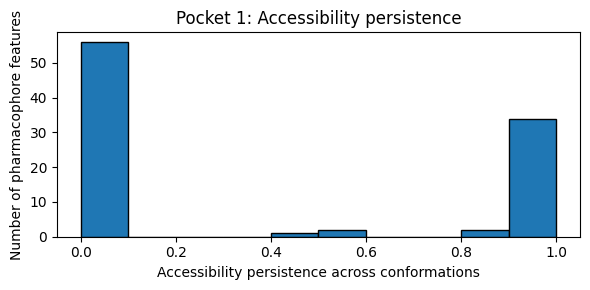

,pocket_id,ca_rmsd_mean,ca_rmsd_sd,clash_mean,clash_max
0,1,0.400002,0.223608,6.8,8


In [44]:
# ==========================================
# 1. FEATURE ACCESSIBILITY PERSISTENCE
# ==========================================

for pid in pocket_feature_sets:

    subset = persistence_df[
        persistence_df["pocket_id"] == pid
    ]

    plt.figure(figsize=(6, 3))

    plt.hist(
        subset["accessibility_persistence"],
        bins=np.linspace(0, 1, 11),
        edgecolor="black"
    )

    plt.xlabel("Accessibility persistence across conformations")
    plt.ylabel("Number of pharmacophore features")
    plt.title(f"Pocket {pid}: Accessibility persistence")

    plt.tight_layout()
    plt.show()


# ==========================================
# 2. COMPACT ENSEMBLE SUMMARY
# ==========================================

ensemble_summary = (
    metrics_df.groupby("pocket_id")
    .agg(
        ca_rmsd_mean=("ca_rmsd_A", "mean"),
        ca_rmsd_sd=("ca_rmsd_A", "std"),
        clash_mean=("nonlocal_vdw_overlaps", "mean"),
        clash_max=("nonlocal_vdw_overlaps", "max")
    )
    .reset_index()
)

display(ensemble_summary)